# Introduction to Jupyter

## What is Jupyter?

The Jupyter Notebook offers an interactive interface to multiple programming languages (including Python and R) that can be viewed and manipulated in web browsers.
 
Jupyter notebooks can run code, and also store the code and a current snapshot of the output (graphics and text), together with notes (in markdown), in an editable document called a *notebook* (like this one you are currently reading).

Thus a Jupyter notebook is similar to a [Mathematica](https://www.wolfram.com/mathematica/)
 or [Maple](https://www.maplesoft.com/) notebook. The difference is that Jupyter is free, fast improving, and unlike Mathematica or Maple notebooks, the Jupyter notebook can support [over 100 programming languages](https://github.com/jupyter/jupyter/wiki/Jupyter-kernels) (more on this {ref}`below <jupyter-kernels>`). Furthermore, Jupyter notebooks are saved on disk as a [JSON](https://www.json.org/) files (with a .ipynb extension), so are fully open source and can be kept under version control.  

### Why use interactive notebooks?

Jupyter is a great tool for "literate programming", a software development style pioneered by Donald Knuth {cite}`Knuth1984LiterateProgramming`. He described the idea this way:
> *Let us change our traditional attitude to the construction of programs: Instead of imagining that our main task is to instruct a computer what to do, let us concentrate rather on explaining to human beings what we want a computer to do.*

In literate programming, human-friendly text is as important as code, making coding accessible to a larger proportion of people. 

And just as importantly, literate programming also helps address the generally poor reproducibility of scientific research by making your code and your methods better reproducible and reusable.

With Jupyter notebooks, you can *explore quantitative ideas* by combining snippets of computer code and human text. The main uses of Jupyter notebooks are:
* Data science (e.g., with [pandas](http://pandas.pydata.org/))
* Mathematical analyses (e.g., with [sympy](http://www.sympy.org/en/index.html))
* Interactive visualization (e.g., with [matplotlib](https://matplotlib.org/) or [ggplot](https://ggplot2.tidyverse.org/))
* Education and teaching
* research communication and reproducibility

Jupyter Notebooks are increasingly being used as a research and teaching tool in academic institutions, government agencies (e.g., NASA, LIGO), as well as industry sectors (e.g., Google, Netflix, Bloomberg). 

## Key Jupyter features

The Jupyter Notebook:

* ...allows you to keep notes using [markdown](https://en.wikipedia.org/wiki/Markdown), the increasingly popular markup language.
* ...offers features available in typical Interactive Development Environments (IDEs) such as code completion and easy access to help.
* ...has LaTeX support. 
* ...can be saved and easily shared in the .ipynb [JSON](https://www.json.org/) (**J**ava**S**cript **O**bject **N**otation &ndash; syntax for storing and exchanging data).
* ...can be kept under version control (e.g., with Git).
* ...can be rendered and viewed online (e.g., on gitHub). 
* ...can be exported to multiple formats, including html, pdf, and slides.

### Jupyter vs. Ipython

[Brian Granger](https://physics.calpoly.edu/bgranger) and [Fernando Pérez](http://fperez.org/) created Ipython (**I**nteractive **Python**) as an implementation of Python for literate programming, taking advantage of improved web browser technologies (e.g., HTML5). Ipython notebooks quickly gained popularity (they were a great alternative to Mathematica and Maple as well), and in 2013 the Ipython team won a Sloan Foundation Grant to accelerate development of this technology. The Ipython Notebook concept was expanded upon to allow for additional programming languages, which became project Jupyter (why "Jupyter"? See [this](https://github.com/jupyter/design/wiki/Jupyter-Logo)). Ipython itself is now focused on the interactive Python project per se, part of which is providing a Python kernel for Jupyter.

*Your Jupyter notebooks will typically open in Ipython as well, but will not allow you Jupyter-only features* (of course!)  

(jupyter-installation)=
## Installing Jupyter

First follow {ref}`python-environments` to choose Python, create a coursework environment and verify its interpreter. Then use {ref}`python-jupyter-install` to install **one** interface into that environment.

### Modern Jupyter Interfaces

* **Jupyter Notebook 7 and newer** provides a focused browser-based notebook interface. It is not the old classic Notebook 6 interface.
* **JupyterLab** provides a tabbed workspace for notebooks, text editors and terminals. It uses the same notebook format and kernel system.
* **VS Code** can open notebooks through its Jupyter extension. Its notebook kernel must be selected independently of any terminal environment. See [VS Code for MQB](../appendices/vscode.md).

The cell-based lessons below apply to both browser interfaces. Some historical screenshots show classic Notebook menus; use the equivalent command in your installed interface rather than downgrading to match an image. There is no need to install both browser interfaces to use obsolete extensions.

### Installing and running Jupyter in a virtual environment

A project environment keeps its Python packages separate from other projects. Use the creation and activation steps in {ref}`python-venv`, then confirm Python and pip agree using {ref}`python-identity`. Keep your notebooks outside the environment directory. Reopen an existing environment by activating it; you do not need to recreate or reinstall it each time.

```{warning}
A virtual environment is not a security sandbox. Notebook code still runs with your account's permissions and can access your files and network. Dependency isolation does not make unfamiliar code safe.
```

The notebook **document**, the browser/editor **interface**, the Jupyter **server**, and the language **kernel** are distinct. The server manages documents and connections; the kernel executes code and holds variables in memory. Installing a package into the server's environment does not install it into every kernel environment.

For package installation, interpreter diagnostics and recreating an environment, use {ref}`python-packages` and {ref}`python-recreate`. Do not modify the MQB book-build environment to run your coursework.

(jupyter-kernels)=
### Language Kernels

The **IPython kernel** (`ipykernel`) runs Python code; other languages need their own kernels. Choose a Python kernel in the notebook's kernel selector, then run this in a **Python code cell**:

```python
import sys
print(sys.executable)
print(sys.version)
print(sys.prefix)
```

Compare the executable with your terminal's {ref}`python-identity` check. A kernel name such as "Python 3" is a label, not proof of which environment is running. If imports fail, first check this path, install the package into that interpreter's environment, and restart the kernel if needed. Changing environments in a separate terminal does not change an already-running kernel.

#### Optional named Python kernel

When the server and coursework kernel use the same environment, the supplied Python kernel is usually enough. If Jupyter runs elsewhere, activate the **coursework Python environment** and register its already-installed `ipykernel`. First inspect `jupyter kernelspec list` and choose an unused name; registration overwrites an existing spec with the same name.

```bash
python -m ipykernel install --user --name mqb-course --display-name "Python (MQB coursework)"
jupyter kernelspec list
```

Here `--user` writes a small kernel registration for your account; it is **not** a `pip --user` package installation. Select "Python (MQB coursework)" in Jupyter and repeat the executable check. The [IPython kernel installation guide](https://ipython.readthedocs.io/en/stable/install/kernel_install.html) also documents registration into a specific server environment with `--prefix`.

Before retiring an environment, stop its kernels, inspect `jupyter kernelspec list`, and remove only its own obsolete registration with `jupyter kernelspec uninstall mqb-course` (substitute the exact name). Review the path and confirmation. This removes the registration, not the Python environment or notebooks; deleting an environment alone can leave a stale kernel entry.

(jupyter-r-kernel)=
#### The R kernel

R needs a separate R installation and the `IRkernel` R package; installing `ipykernel` does not provide R. Complete [R Installation and User Libraries](../appendices/r-setup.md) first, then start `R` from a terminal where the intended Jupyter installation is available. In the **R console**, inspect `R.home()`, `.libPaths()` and `Sys.which("jupyter")`. If Jupyter is missing, fix that terminal's environment before registration.

For a machine with the required R/compiler/system-library prerequisites, install the released CRAN package into your writable R library and register it for your account:

```r
install.packages("IRkernel", repos = "https://cloud.r-project.org")
IRkernel::installspec(user = TRUE, name = "mqb-r", displayname = "R (MQB)")
```

Choose an unused registration name first. Follow the current [IRkernel installation and platform requirements](https://irkernel.github.io/installation/) when dependencies need compiling; do not install arbitrary system libraries merely because an R installation failed. A development GitHub install via `devtools` is not the normal CRAN route. After selecting "R (MQB)" in Jupyter, check `R.version.string`, `R.home()` and `.libPaths()` in an **R cell**, not a Python cell. Python virtual environments do not isolate R packages. R-kernel runtime verification is separate from the Python checks.

(jupyter-extensions)=
### Adding extensions to Jupyter

Start with the interface's built-in facilities, including its table of contents, before adding extensions. Classic Notebook extensions such as `jupyter_contrib_nbextensions` and its configurator are not drop-in additions to Notebook 7 or JupyterLab. Consult the [Notebook 7 migration guide](https://jupyter-notebook.readthedocs.io/en/stable/migrate_to_notebook7.html) and each extension's supported interface/version before installing it.

For an extension you actually need, review its publisher and permissions, follow its current installation instructions in the **server/interface environment**, and test it on a disposable notebook. Record how to disable or uninstall it. An extension that can execute code has your account's permissions. Do not enable all extensions or downgrade the main coursework environment just to reproduce a classic screenshot.

## Launching/running a Jupyter Notebook

Keep a coursework notebook in the [project root](../appendices/terms.md#project-root), alongside `code/`, `data/` and `results/`. In Linux or macOS, change to that root in a terminal, confirm it with `pwd`, activate the project's Python environment, then launch the interface you installed:

```bash
jupyter lab  # or: jupyter notebook
```

This starts a local server and opens its browser interface. Keep the terminal open while you use it.

Play around a bit. For starters,

$\star$ Create a new notebook called `MyFirstJupyterNb.ipynb` in the project root. Do not put it inside `code/`: keeping it beside the three project directories lets both scripts and notebooks use paths such as `data/input.csv` and `results/figure.png`.

The next time you work on it, return to the project root and launch it by name:

```bash
jupyter notebook MyFirstJupyterNb.ipynb
```

```{note}
**macOS users**: The process is identical on macOS. The terminal commands work the same whether you're using the default Terminal app, iTerm2, or any other terminal emulator. Just make sure you've activated your virtual environment first if you're using one.
```

### Using `tmux`
You may notice that jupyter locks up the terminal you launch it from until it is closed. This can be particularly frustrating, and there is an elegant solution. Enter `tmux`!

`tmux` is a "terminal multiplexer", allowing you to run terminal sessions independent of (or "detached" from) a terminal window. You can install tmux using apt:

``` bash
sudo apt install tmux
```

#### Detaching and reattaching
To run jupyter in a tmux session, start tmux using the command `tmux`. From here you can use the tmux terminal as you would your usual terminal session (so launch `jupyter notebook` as before), however if at any time you decide that you want to do something else, you can **detach**.

To detach your terminal window from the session, use the shortcut `ctrl+b, d` (ctrl+b, then let go of that and hit d). This kicks you back to the normal terminal, however your other session is still running in the background.

To see which sessions are currently running, use
``` bash
tmux ls
```

And to attach to the session:
``` bash
tmux a
```

*Note: you can attach to a session from a different terminal window or even terminal program!*

To quit tmux entirely, just quit the terminal session either with `ctrl+d` or `exit`

#### Why use `tmux`?
While this is mostly just a quality of life suggestion, countless are the times that I have accidentally closed my terminal only to find that my jupyter session has also died. By decoupling the window from the terminal session, this no longer happens.

Additionally tmux is absolutely invaluable when running long jobs on a remote server. In this case you can simply disconnect from the tmux session on the remote server. Then you can log in later (and/or from a different computer) and **reattach to the interactive session** (using `tmux a`) to check progress. In combination with good logging for long jobs, this can make your life infinitely easier.

## Using Jupyter in VS Code

VS Code can keep notebooks, scripts and an integrated terminal in one project window. Follow [VS Code for MQB](../appendices/vscode.md) to install the Microsoft Python and Jupyter extensions, open a project folder, select the intended interpreter and choose a notebook kernel.

Open the project root as the VS Code folder and keep the notebook itself in that root. A notebook's kernel is separate from the terminal and can retain variables between runs. Check both `sys.executable` and `Path.cwd()` in the first Python cell, save before changing kernels, and restart the kernel before a clean reproducibility run. The setup page explains this process; {ref}`jupyter-kernels` covers named Python and R kernels.

## Key elements of the Jupyter nb content

The two main elements (and the associated syntax) you need to know to modify the content of a Jupyter nb are as follows. These will either be entered into text-only cells ("markdown cells"), or code cells. To insert a new cell, click on the edge of an existing cell, and hit `A` or `B` on your keyboard to insert a cell above and below, respectively. By default, Jupyter inserts a code cell. To convert it to a text cell, hit `M` immediately after inserting the cell, or if you have clicked elsewhere after inserting the cell, by clicking on the edge of the new cell and *then* hitting `M`. You can now either enter and modify text or code:   

###  Text cells

Text is formatted using markdown and standard html. The [markdown cheatsheet for github](https://github.com/adam-p/markdown-here/wiki/Markdown-Cheatsheet) is very handy. Give it a quick spin to get started with markdown.  

#### Equations

You can insert inline or standalone equations by using standard $\LaTeX$ environments (and you can access more $\LaTeX$ functionality and environments using the [`la-te-x_envs` extension](https://github.com/jfbercher/jupyter_latex_envs).). For example, how about the ecologist's beloved logistic growth equation:

```tex
$$
    \frac{dN}{dt} = rN \left( 1-\frac{N}{K}\right)
$$
```

which will render as: 


$$\frac{dN}{dt} = rN \left( 1-\frac{N}{K}\right)$$

### Code cells 

Depending on your kernel, you will type the appropriate programming language code in these cells.  

## Keyboard shortcuts

A full list of keyboard shortcuts can be displayed by clicking outside the current cell and hitting "h". The following are important keyboard shortcuts:

| Key            | Command                                                    |
|:---------------|:-----------------------------------------------------------|
| `A` or `B`:    | insert cell above or below current cell, respectively      |
| `M`       :    | convert code or raw cell to text cell                      |
| `Y`        :   | convert raw or text cell to code cell                      |
| `R`        :   | convert code or text cell to raw cell                      |
| `CTRL+ENTER`:  | render (text) or evaluate (code) cell                      |
| `D, D`:        | delete cell                                                |
| `I, I`:        | interrupt a running kernel (evaluation of a code cell)     |
| `X`:        | cut selected cell(s)     |
| `SHIFT+V`:        | Insert cell(s) cell above selected cell     |
| `V`:        | Insert cut cell(s)  below selected cell     |
| `SHIFT+M`:        | merge selected cells, or current cell with cell below if only one cell selected |


For a full list of keyboard shortcuts or to cutomize them, click anywhere outside your current cell and hit the `H` key. Or, click on the "help" menu item at the top.

## Running code 

Let's try running code in a code cell. Python first. Make sure that your kernel is Python using the dropdown Jupyter nb menu. Then try the following:

In [1]:
a = "this is python!"; print(a)

this is python!


You can also run a script file that is saved on your computer by using the  ipython `%run` command --- basically you have a fully functional ipython environment inside each code cell.

Now R. Switch the kernel to R by using the *Kernel* menu along the top of the Jupyter window. 

Then try:

In [1]:
a <- "this is r!"; cat(a)

this is r!

### Graphics

Plotting is straightforward. Again, let's try Python first. Switch back to the Python kernel. Then try:

```{note}
In Jupyter notebooks, you typically need to use `%matplotlib inline` to display plots inline. In VS Code, this is handled automatically.
```

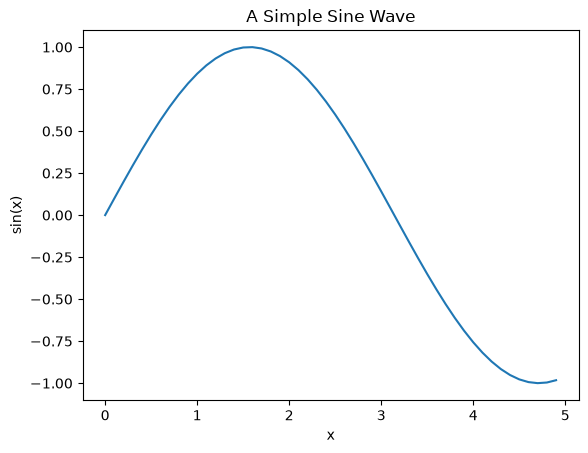

In [2]:
%matplotlib inline
import matplotlib.pyplot as p
import numpy as np

x = np.arange(0, 5, 0.1)
y = np.sin(x)
p.plot(x, y)
p.xlabel('x')
p.ylabel('sin(x)')
p.title('A Simple Sine Wave')
p.show()

Now let's try R. Switch to the R kernel, and try:

```{tip}
For interactive visualizations, you might also explore libraries like [plotly](https://plotly.com/) (python) or [plotly for R](https://plotly.com/r/), which create interactive plots that you can zoom, pan, and hover over.
```

Loading required package: ggplot2



Warning message:
“`qplot()` was deprecated in ggplot2 3.4.0.”


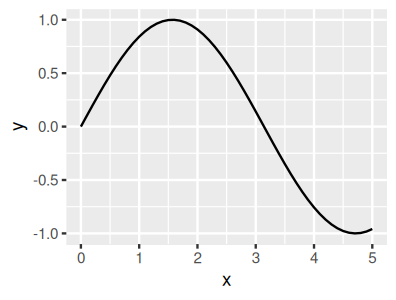

In [2]:
require(ggplot2)
library(repr)# to resize plot within jupyter - this package is part of IrKernel
options(repr.plot.width=3.3,repr.plot.height=2.5)

x <- seq(0, 5, 0.1); y <- sin(x)
qplot(x, y, geom = "line") # large figure

## Exiting a Jupyter Notebook

Exiting is easy. Just `Ctrl+S` (or `Cmd+S` on macOS) to save and close the browser. The server will still be active in the bash terminal. You may then relaunch by typing the local url (e.g., by typing `http://localhost:8888/notebooks/MyJupyterNbName.ipynb`) in your web browser window, or by exiting the kernel with `Ctrl+C` (or `Cmd+C` on macOS) and then relaunching as described in {ref}`the installation guidance <jupyter-installation>`.

```{note}
If you're using VS Code, simply close the notebook tab. The kernel will stop automatically when VS Code closes, or you can manually stop it using the kernel status button in the top right of the notebook.
```

## Congratulations!

You've completed the introduction to Jupyter notebooks! You should now understand:

* What Jupyter is and why it's useful for scientific computing and literate programming
* How to install and set up Jupyter on both Linux and macOS
* Different ways to use Jupyter (classic notebook, JupyterLab, VS Code)
* How to create, run, and manage notebooks
* Best practices for creating reproducible, maintainable notebooks

Play around a bit with what you've learned. You can also try out the [Data in Jupyter](appendix-data-python.ipynb) and [Maths in Jupyter](appendix-maths.ipynb) tutorials to continue learning.

## Best Practices for Jupyter Notebooks

As you develop your skills with Jupyter notebooks, following these best practices will help you create more maintainable, reproducible, and professional work:

### Organization and Structure

* **Use descriptive cell titles**: Add markdown cells with headers to organize your notebook into logical sections
* **One concept per cell**: Keep code cells focused on a single task or concept
* **Maintain logical flow**: Execute cells in order from top to bottom; avoid jumping around
* **Document as you go**: Add explanatory text before complex code blocks

### Code Quality

* **Import all libraries at the top**: Keep all `import` statements in the first code cell
* **Use meaningful variable names**: Avoid single letters except for common conventions (e.g., `x`, `y` for coordinates)
* **Add comments**: Explain *why* you're doing something, not just *what* you're doing
* **Keep cells reasonably sized**: If a cell is getting too long, consider breaking it up

### Version Control

* **Clear outputs before committing**: Use "Clear All Outputs" before committing to Git
  - This keeps diffs clean and reduces file size
  - In VS Code: right-click notebook → "Clear All Outputs"
  - In Jupyter: Kernel → restart & Clear Output

* **Use `.gitignore`**: Add common files to `.gitignore`:
  ```
  .ipynb_checkpoints/
  __pycache__/
  *.pyc
  ```

* **Consider `nbstripout`**: This tool automatically removes outputs when committing:
  ```bash
  pip install nbstripout
  nbstripout --install
  ```

### Reproducibility

* **Document your environment**: Create a `requirements.txt` file:
  ```bash
  pip freeze > requirements.txt
  ```

* **Set random seeds**: When using random numbers, set seeds for reproducibility:
  ```python
  import numpy as np
  np.random.seed(42)
  ```

* **Restart and run all**: For a single-language analysis notebook, periodically test that it runs from start to finish:
  - Kernel → restart & run All

* **Check the working directory before using a relative path**: A notebook kernel does not necessarily start at the project root. Keep your coursework notebook in the root, inspect the location in its first cell, and stop early if the expected project folders are absent:
  ```python
  from pathlib import Path
  project_root = Path.cwd()
  required = [project_root / name for name in ("code", "data", "results")]
  missing = [path.name for path in required if not path.is_dir()]
  if missing:
      raise FileNotFoundError("Open this notebook from the project root; missing: " + ", ".join(missing))
  ```

### Performance and resources

* **Close notebooks when done**: Notebooks continue to use memory even when idle
* **Monitor memory usage**: Large datasets can exhaust memory; consider:
  - Processing data in chunks
  - Using data types efficiently (e.g., `int32` instead of `int64` when appropriate)
  - Clearing large variables with `del variable_name`

* **Use `%%time` for profiling**: Add `%%time` at the start of a cell to measure execution time

### Sharing and Collaboration

* **Clear sensitive information**: remove API keys, passwords, and personal data before sharing
* **Add a readme**: Include a markdown cell at the top explaining:
  - Purpose of the notebook
  - required dependencies
  - How to run it
  - Author and date

* **Export when appropriate**: Share notebooks as:
  - HTML for non-technical audiences (File → Download as → HTML)
  - PDF for reports and submissions
  - Python scripts for production code (File → Download as → Python)

### macOS-Specific Tips

* **Use `Cmd+S` frequently**: Save your work regularly (or enable auto-save)
* **Terminal integration**: macOS terminal commands work in notebook cells with `!` prefix:
  ```ipython
  !ls -la
  !pwd
  ```
* **File paths**: macOS uses forward slashes like Linux (`/Users/...`)
* **Hidden files**: Use `!ls -la` to see hidden files starting with `.`

```{tip}
For coursework submissions, restart the selected kernel and run all cells from top to bottom. This introductory page is an exception because it asks you to switch the whole notebook between Python and R for short demonstrations; apply the check to each of your own single-language analysis notebooks.
```

## Readings & Resources

* Check out [github flavored markdown](https://guides.github.com/features/mastering-markdown/), [markdown cheatsheet for github](https://github.com/adam-p/markdown-here/wiki/Markdown-Cheatsheet), and [also this](https://en.support.wordpress.com/markdown-quick-reference/)
* [A gallery of interesting Jupyter Notebooks
](https://github.com/jupyter/jupyter/wiki/A-gallery-of-interesting-Jupyter-Notebooks)
* [Python Data Science Handbook](https://github.com/jakevdp/pythonDataScienceHandbook)
* [Scientific Python Lectures in Jupyter](https://github.com/jrjohansson/scientific-Python-lectures)